In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from collections import Counter

# Models
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import lightgbm as lgb
import xgboost as xgb

# Deep Learning Libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, Flatten, LSTM
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import BatchNormalization , GlobalAveragePooling1D

# Ignore all warnings
import warnings
warnings.filterwarnings('ignore')

### 1. EDA (Exploratory Data Analysis)

In [52]:
# 1. DATA LOADING & CLEANING
df = pd.read_csv("/kaggle/input/datasets/tahafarooqkhan/cicmaldroid-2020/feature_vectors_syscalls_frequency_5_Cat.csv")
print("Dynamic Dataset Loaded...")

Dynamic Dataset Loaded...


In [53]:
print(f"Dynamic Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
df.head()

Dynamic Dataset Shape: (11598, 140)

First 5 rows:


,__arm_nr_cacheflush,__arm_nr_set_tls,_llseek,_newselect,accept,access,bind,brk,capset,chdir,...,ugetrlimit,umask,uname,unlink,utimes,vfork,wait4,write,writev,Class
0,0.0,14.0,6.0,0.0,0.0,11.0,3.0,21.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,37.0,10.0,1.0
1,1590.0,42.0,6.0,0.0,0.0,47.0,2.0,1430.0,1.0,0.0,...,2.0,0.0,1.0,4.0,0.0,0.0,0.0,2840.0,46.0,1.0
2,0.0,23.0,6.0,0.0,0.0,40.0,9.0,89.0,1.0,0.0,...,0.0,0.0,1.0,2.0,0.0,0.0,0.0,111.0,20.0,1.0
3,0.0,27.0,6.0,0.0,0.0,60.0,1.0,242.0,1.0,0.0,...,0.0,0.0,1.0,2.0,0.0,0.0,0.0,987.0,197.0,1.0
4,0.0,18.0,6.0,0.0,0.0,26.0,5.0,59.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,98.0,25.0,1.0


In [54]:
df['Class'].unique()

array([1., 2., 3., 4., 5.])

### I. CLEANING: 
Remove ugly trailing underscores (e.g., 'EXECUTE_____' -> 'EXECUTE')

In [55]:
df.columns = df.columns.str.replace(r'_+$', '', regex=True)

#### Checking for Missing and Duplicates and handling them

In [56]:
print("\nMissing Values:\n", df.isnull().sum().sum())


Missing Values:
 0


In [57]:
print("\nDuplicate Rows:\n", df.duplicated().sum())



Duplicate Rows:
 77


In [58]:
df.drop_duplicates(inplace=True)

In [59]:
print("\nDuplicate Rows:\n", df.duplicated().sum())


Duplicate Rows:
 0


### II. Checking if the dataset is balanced

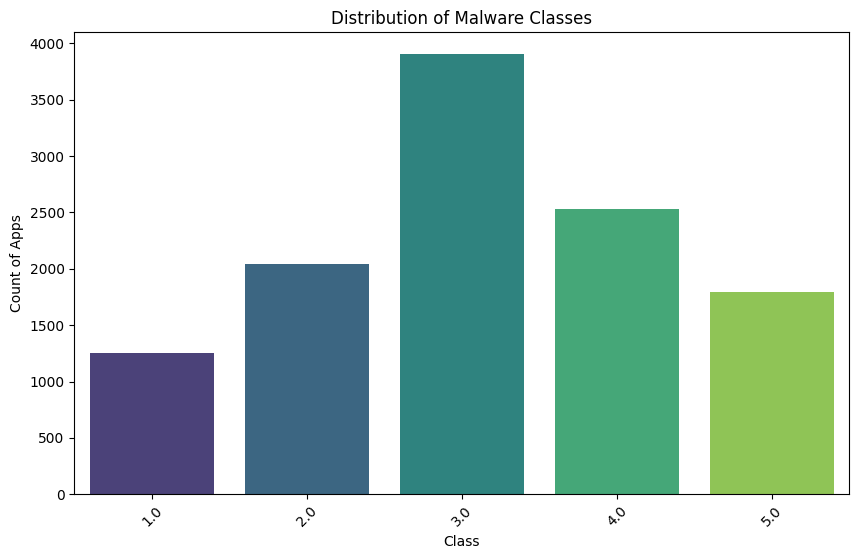

In [60]:
# 1. Check Class Balance
plt.figure(figsize=(10, 6))
sns.countplot(x=df['Class'], palette='viridis')
plt.title("Distribution of Malware Classes")
plt.xlabel("Class")
plt.ylabel("Count of Apps")
plt.xticks(rotation=45)
plt.show()

### The Class Imbalance

**Diagnosis:** Our classes are not equal. Class 3 (SMS Malware) has ~3900 samples, while Class 1 (Adware) has only ~1200.

**Risk:** If we don't fix this, the model will be "lazy" and just guess "Class 3" often because it's the safest bet.

#### Class Mapping (Based on counts):

1: Adware (~1300)

2: Banking (~2100)

3: SMS (~3900) (**Largest**)

4: Riskware (~2500)

5: Benign (~1700)

We will use **SMOTE** for Data Balancing

### III. Define Target & Features

In [61]:
# Dropping off redundant 'EXECUTE' and all label columns
drop_cols = ['Class', 'Class_Encoded', 'EXECUTE']
X_raw = df.drop(columns=[c for c in df.columns if c in drop_cols or 'class' in c.lower()], errors='ignore')

# Encoding Target
le = LabelEncoder()
y = le.fit_transform(df['Class'])
class_names = le.classes_
print(f"Data Shape: {X_raw.shape}")
print(f"Classes: {class_names}")

Data Shape: (11521, 139)
Classes: [1. 2. 3. 4. 5.]


### 2. UNIVERSAL SPLITTING & SCALING

In [62]:
# SPLIT (80% Train, 20% Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y)

In [63]:
print(f" Original Training Counts: {Counter(y_train)}")

 Original Training Counts: Counter({np.int64(2): 3122, np.int64(3): 2023, np.int64(1): 1635, np.int64(4): 1434, np.int64(0): 1002})


In [64]:
# SCALING (Required for SVM, KNN, CNN, LSTM)
# We use StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

In [65]:
joblib.dump(scaler, '/kaggle/working/scaler.pkl') 

print("Scaler saved successfully!")

Scaler saved successfully!


Applying **SMOTE**

In [66]:
smote = SMOTE(random_state=42)

In [67]:
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

In [68]:
print(f"New SMOTE Training Counts: {Counter(y_train_smote)}")

New SMOTE Training Counts: Counter({np.int64(3): 3122, np.int64(2): 3122, np.int64(1): 3122, np.int64(4): 3122, np.int64(0): 3122})


In [69]:
# We reshape the *balanced* SMOTE data for CNN/LSTM/HYBRID training
X_train_dl = X_train_smote.reshape(X_train_smote.shape[0], X_train_smote.shape[1], 1)
y_train_dl = to_categorical(y_train_smote)

# We reshape the *original* Test data for evaluation (We Never SMOTE the test set)
X_test_dl = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)
y_test_dl = to_categorical(y_test)

print("\nData Preparation with SMOTE Complete.")
print(f" - Training Data (SMOTE): {X_train_smote.shape}")
print(f" - Test Data (Original):  {X_test_scaled.shape}")


Data Preparation with SMOTE Complete.
 - Training Data (SMOTE): (15610, 139)
 - Test Data (Original):  (2305, 139)


In [70]:
# One-Hot Encoding for Deep Learning Targets
# y_train_dl = to_categorical(y_train)
# y_test_dl = to_categorical(y_test)

In [71]:
print("Data Preparation Complete:")
print(f" - Tree Data (Raw):    {X_train_raw.shape}")
print(f" - Scaled Data (SVM):  {X_train_scaled.shape}")
print(f" - Deep Learning Data: {X_train_dl.shape}")

Data Preparation Complete:
 - Tree Data (Raw):    (9216, 139)
 - Scaled Data (SVM):  (9216, 139)
 - Deep Learning Data: (15610, 139, 1)


### 3. TRADITIONAL ML MODELS

Helper Functions to assist

In [72]:
# Dictionary to store results
model_results = {}

# HELPER FUNCTION FOR PLOTTING
def plot_results(name, y_true, y_pred):
    # Classification Report
    print(f"\n --- {name} REPORT ---")
    # Converting class names to strings
    print(classification_report(y_true, y_pred, target_names=[str(c) for c in class_names]))
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Function for Model Training and Evaluation
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    print(f"\n Training {name}...")
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    acc = accuracy_score(y_te, preds)
    print(f" {name} Accuracy: {acc:.4f}")
    model_results[name] = acc
    
    # Call the helper
    plot_results(name, y_te, preds)
    return model

### A. Random Forest


 Training Random Forest...
 Random Forest Accuracy: 0.9427

 --- Random Forest REPORT ---
              precision    recall  f1-score   support

         1.0       0.91      0.91      0.91       251
         2.0       0.94      0.92      0.93       409
         3.0       0.97      0.99      0.98       781
         4.0       0.94      0.93      0.94       506
         5.0       0.89      0.91      0.90       358

    accuracy                           0.94      2305
   macro avg       0.93      0.93      0.93      2305
weighted avg       0.94      0.94      0.94      2305



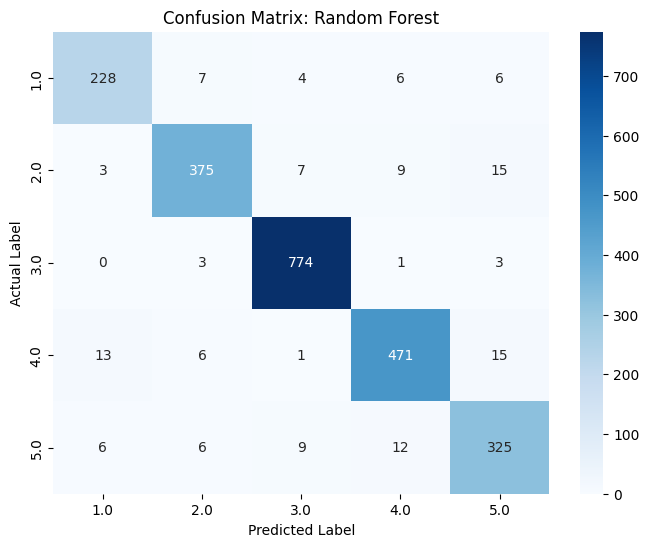

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [73]:
rf = RandomForestClassifier(n_estimators=200, 
                            class_weight='balanced', 
                            random_state=42, 
                            n_jobs=-1)
evaluate_model("Random Forest", rf, X_train_raw, X_test_raw, y_train, y_test)

In [74]:
# Exporting RF
joblib.dump(rf, "/kaggle/working/random_forest_model.pkl")

['/kaggle/working/random_forest_model.pkl']

 ### B. LightGBM


 Training LightGBM...
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 13182
[LightGBM] [Info] Number of data points in the train set: 9216, number of used features: 109
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 56 dense feature groups (0.49 MB) transferred to GPU in 0.000898 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
 LightGBM Accuracy: 0.9501

 --- LightGBM REPORT ---
              precision    recall  f1-score   support

         1.0       0.89      0.92      0.90       251
         2.0       0.95      0.9

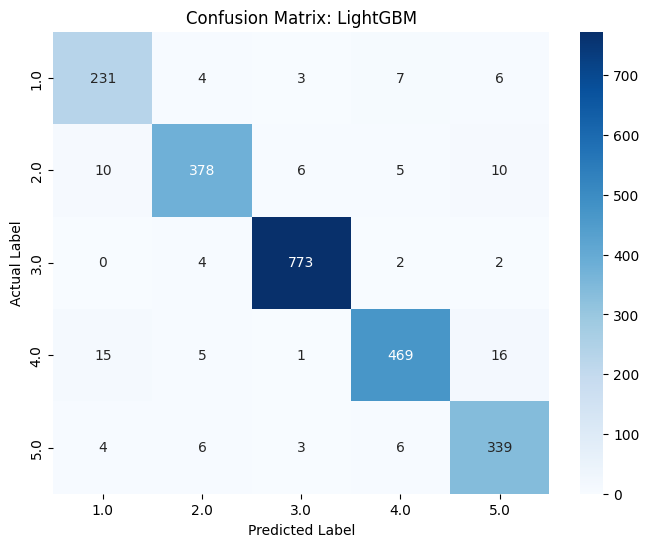

LGBMClassifier(class_weight='balanced', device='gpu', learning_rate=0.05,
               n_estimators=200, random_state=42)

In [75]:
lgbm = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    device='gpu'
)
evaluate_model("LightGBM", lgbm, X_train_raw, X_test_raw, y_train, y_test)

In [76]:
joblib.dump(lgbm, "/kaggle/working/light_gbm_model.pkl")

['/kaggle/working/light_gbm_model.pkl']

###  C. XGBoost 




 Training XGBoost...
 XGBoost Accuracy: 0.9410

 --- XGBoost REPORT ---
              precision    recall  f1-score   support

         1.0       0.90      0.91      0.90       251
         2.0       0.94      0.90      0.92       409
         3.0       0.97      0.99      0.98       781
         4.0       0.95      0.94      0.94       506
         5.0       0.90      0.91      0.90       358

    accuracy                           0.94      2305
   macro avg       0.93      0.93      0.93      2305
weighted avg       0.94      0.94      0.94      2305



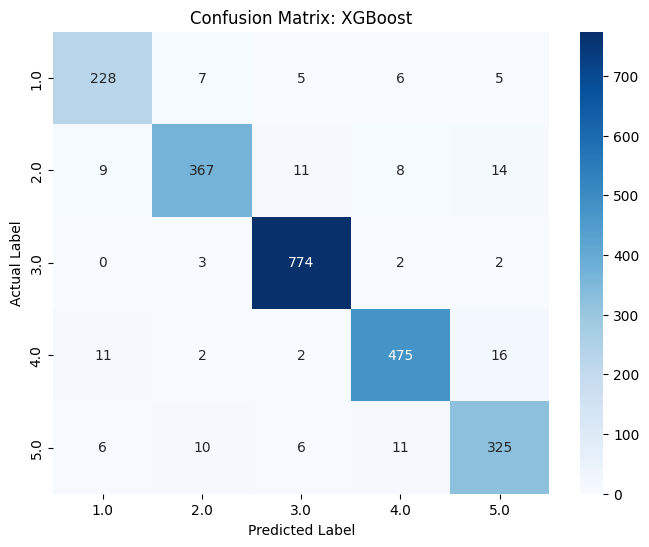

['/kaggle/working/xgboost_model.pkl']

In [77]:
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    tree_method='hist', 
    device='cuda'           
)
evaluate_model("XGBoost", xgb_model, X_train_raw, X_test_raw, y_train, y_test)

# XGBoost requires classes to be 0,1,2... which we did with LabelEncoder

# Exporting
joblib.dump(xgb_model, "/kaggle/working/xgboost_model.pkl")

### D. SVM (Support Vector Machine)



 Training SVM...
 SVM Accuracy: 0.7349

 --- SVM REPORT ---
              precision    recall  f1-score   support

         1.0       0.53      0.56      0.54       251
         2.0       0.68      0.54      0.60       409
         3.0       0.73      0.92      0.82       781
         4.0       0.83      0.68      0.75       506
         5.0       0.85      0.76      0.80       358

    accuracy                           0.73      2305
   macro avg       0.72      0.69      0.70      2305
weighted avg       0.74      0.73      0.73      2305



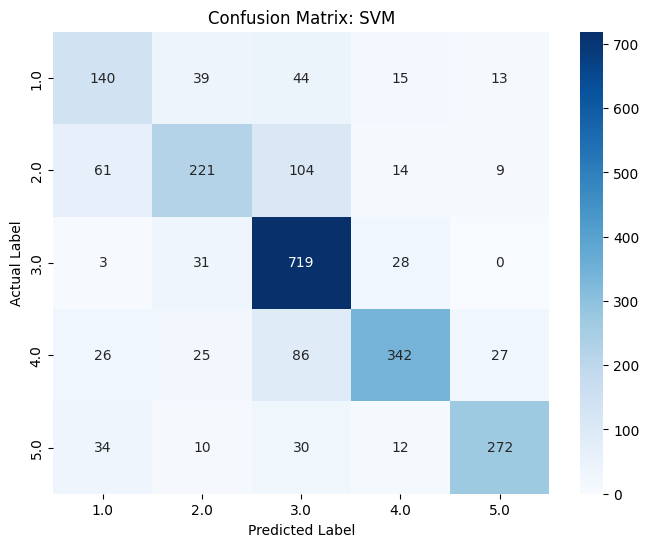

['/kaggle/working/svm_model.pkl']

In [78]:
# We Must use Scaled Data. 'rbf' kernel is best for complex boundaries.
svm = SVC(kernel='rbf', 
          C=1.0, 
          class_weight='balanced', 
          random_state=42,)
evaluate_model("SVM", svm, X_train_scaled, X_test_scaled, y_train, y_test)

#Exporting
joblib.dump(svm, "/kaggle/working/svm_model.pkl")

### E. KNN (K-Nearest Neighbors)


 Training KNN...
 KNN Accuracy: 0.8894

 --- KNN REPORT ---
              precision    recall  f1-score   support

         1.0       0.76      0.82      0.79       251
         2.0       0.89      0.88      0.88       409
         3.0       0.94      0.99      0.96       781
         4.0       0.89      0.88      0.89       506
         5.0       0.88      0.74      0.80       358

    accuracy                           0.89      2305
   macro avg       0.87      0.86      0.86      2305
weighted avg       0.89      0.89      0.89      2305



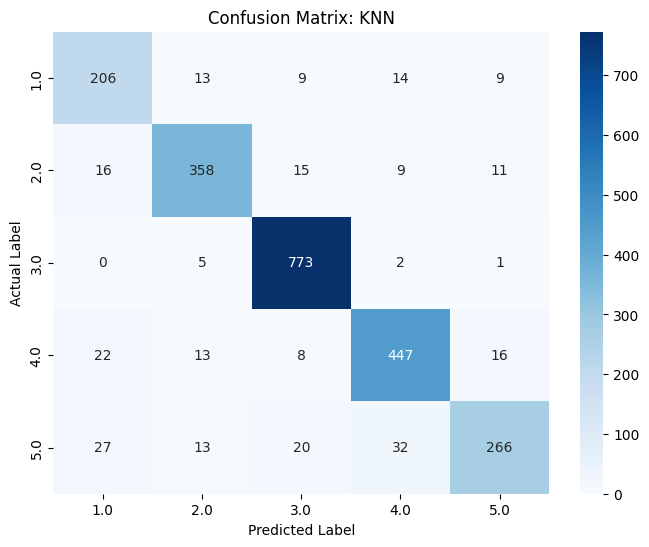

['/kaggle/working/knn_model.pkl']

In [79]:
# We must use Scaled Data.
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski')
evaluate_model("KNN", knn, X_train_scaled, X_test_scaled, y_train, y_test)

#Exporting
joblib.dump(knn, "/kaggle/working/knn_model.pkl")

### F. Naive Bayes


 Training Naive Bayes...
 Naive Bayes Accuracy: 0.4920

 --- Naive Bayes REPORT ---
              precision    recall  f1-score   support

         1.0       0.19      0.45      0.26       251
         2.0       0.69      0.10      0.17       409
         3.0       0.55      0.99      0.71       781
         4.0       0.88      0.14      0.24       506
         5.0       0.89      0.39      0.54       358

    accuracy                           0.49      2305
   macro avg       0.64      0.41      0.39      2305
weighted avg       0.66      0.49      0.44      2305



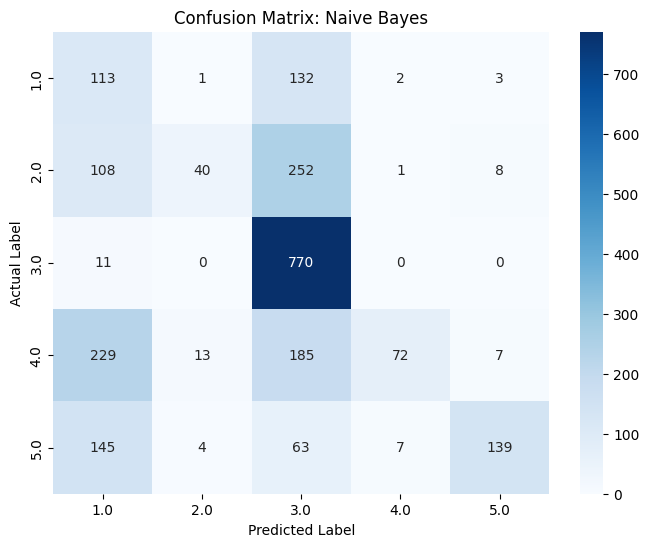

['/kaggle/working/nb_model.pkl']

In [80]:
# We use GaussianNB because our scaled data has negative values (StandardScaler)
nb = GaussianNB()
evaluate_model("Naive Bayes", nb, X_train_scaled, X_test_scaled, y_train, y_test)

#Exporting
joblib.dump(nb, "/kaggle/working/nb_model.pkl")

### 4. DEEP LEARNING MODELS




In [81]:
input_shape = (X_train_dl.shape[1], 1)
num_classes = y_train_dl.shape[1]
epochs = 20
batch_size = 32

Helper function for DL

In [82]:
def train_dl_model(name, model, X_tr, y_tr, X_te, y_te_onehot, y_te_original):
    print(f"\n Training {name} (Deep Learning)...")
    
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    
    # Train
    model.fit(X_tr, y_tr, epochs=epochs, batch_size=batch_size, 
              validation_data=(X_te, y_te_onehot), verbose=0)
    # Predict
    y_pred_probs = model.predict(X_te)
    # Convert Probabilities to Class Integers (0, 1, 2...)
    y_pred_indices = np.argmax(y_pred_probs, axis=1)
    # Calculate Accuracy
    acc = accuracy_score(y_te_original, y_pred_indices)
    print(f" {name} Accuracy: {acc:.4f}")
    model_results[name] = acc
    # Plot Reports
    plot_results(name, y_te_original, y_pred_indices)
    return model

### G. CNN

In [83]:
cnn = Sequential([
    Conv1D(64, 3, activation='relu', input_shape=input_shape),    
    MaxPooling1D(2),
    Conv1D(128, 3, activation='relu'),
    MaxPooling1D(2),
    Conv1D(256, 3, activation='relu'),
    MaxPooling1D(2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])


 Training CNN (Deep Learning)...
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
 CNN Accuracy: 0.9197

 --- CNN REPORT ---
              precision    recall  f1-score   support

         1.0       0.83      0.89      0.86       251
         2.0       0.93      0.89      0.91       409
         3.0       0.96      0.99      0.97       781
         4.0       0.90      0.91      0.90       506
         5.0       0.92      0.84      0.88       358

    accuracy                           0.92      2305
   macro avg       0.91      0.90      0.90      2305
weighted avg       0.92      0.92      0.92      2305



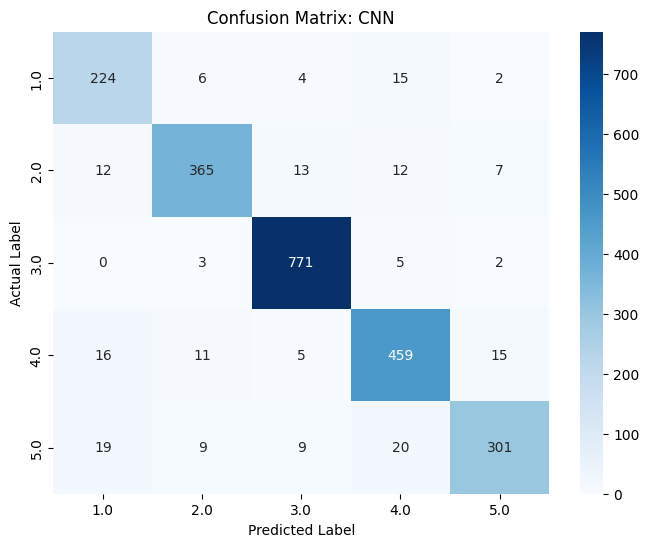

<Sequential name=sequential_3, built=True>

In [84]:
train_dl_model("CNN", cnn, X_train_dl, y_train_dl, X_test_dl, y_test_dl, y_test)

### H. LSTM

In [85]:
lstm = Sequential([ 
    LSTM(64, return_sequences=True, input_shape=input_shape), 
    Dropout(0.3), 
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(256),
    Dropout(0.5),
    Dense(128, activation='relu'), 
    Dropout(0.5), 
    Dense(num_classes, activation='softmax') ])


 Training LSTM (Deep Learning)...
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
 LSTM Accuracy: 0.8126

 --- LSTM REPORT ---
              precision    recall  f1-score   support

         1.0       0.57      0.78      0.65       251
         2.0       0.80      0.73      0.76       409
         3.0       0.90      0.95      0.93       781
         4.0       0.84      0.76      0.80       506
         5.0       0.82      0.70      0.75       358

    accuracy                           0.81      2305
   macro avg       0.79      0.78      0.78      2305
weighted avg       0.82      0.81      0.81      2305



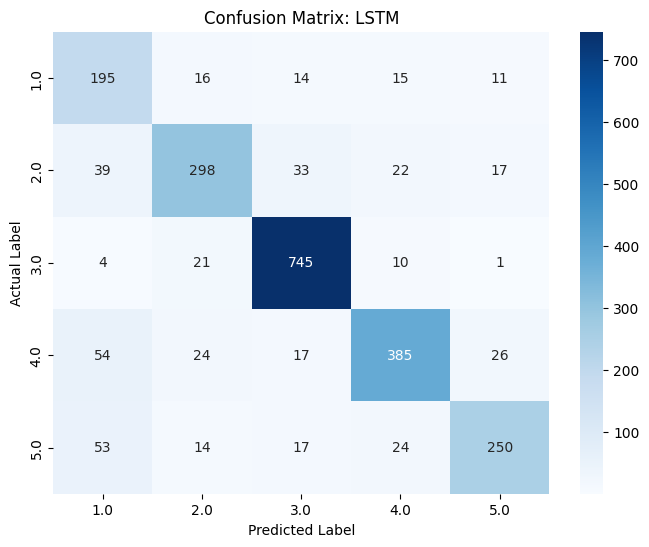

<Sequential name=sequential_4, built=True>

In [86]:
train_dl_model("LSTM", lstm, X_train_dl, y_train_dl, X_test_dl, y_test_dl, y_test)

### I. Hybrid CNN + LSTM

In [87]:
hybrid = Sequential([
    
    Conv1D(64, 3, activation='relu', input_shape=input_shape),
    MaxPooling1D(2),

    Conv1D(128, 3, activation='relu'),
    MaxPooling1D(2),

    Conv1D(128, 3, activation='relu'),
    MaxPooling1D(2),
    
    LSTM(64, return_sequences=True), 
    Dropout(0.3),
    
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    
    LSTM(256, return_sequences=False),

    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')  
])


 Training Hybrid CNN-LSTM (Deep Learning)...
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
 Hybrid CNN-LSTM Accuracy: 0.8902

 --- Hybrid CNN-LSTM REPORT ---
              precision    recall  f1-score   support

         1.0       0.76      0.87      0.81       251
         2.0       0.92      0.83      0.87       409
         3.0       0.97      0.98      0.97       781
         4.0       0.82      0.90      0.86       506
         5.0       0.91      0.76      0.83       358

    accuracy                           0.89      2305
   macro avg       0.87      0.87      0.87      2305
weighted avg       0.89      0.89      0.89      2305



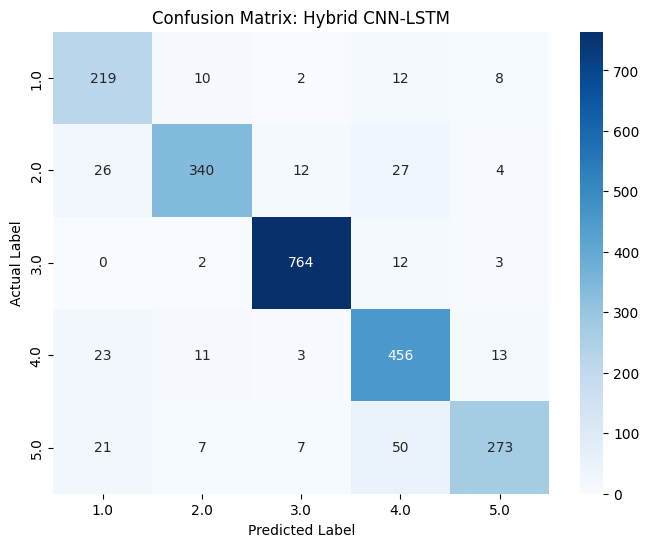

<Sequential name=sequential_5, built=True>

In [88]:
train_dl_model("Hybrid CNN-LSTM", hybrid, X_train_dl, y_train_dl, X_test_dl, y_test_dl, y_test)

In [89]:
cnn.save("/kaggle/working/cnn.keras")
lstm.save("/kaggle/working/lstm.keras")
hybrid.save("/kaggle/working/hybrid.keras")
print("Models Exported")

Models Exported


In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_top_weakest_cm(models_dict, X_test_data, y_test_true):
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # Models to plot as per request
    target_models = ['Hybrid CNN-LSTM', 'Random Forest', 'Naive Bayes']
    
    for i, model_name in enumerate(target_models):
        model = models_dict[model_name]
        # Handle DL models which need reshaped data
        if 'CNN' in model_name or 'LSTM' in model_name:
            y_pred = np.argmax(model.predict(X_test_dl), axis=1) + 1 # +1 if labels start at 1
        else:
            y_pred = model.predict(X_test_raw)
            
        cm = confusion_matrix(y_test_true, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
        axes[i].set_title(f'Confusion Matrix: {model_name}')
        axes[i].set_xlabel('Predicted')
        axes[i].set_ylabel('Actual')

    plt.tight_layout()
    plt.show()

# Usage (assuming your models are loaded/trained):
# models_list = {'Hybrid CNN-LSTM': hybrid, 'Random Forest': rf, 'Naive Bayes': nb}
# plot_top_weakest_cm(models_list, X_test_raw, y_test)


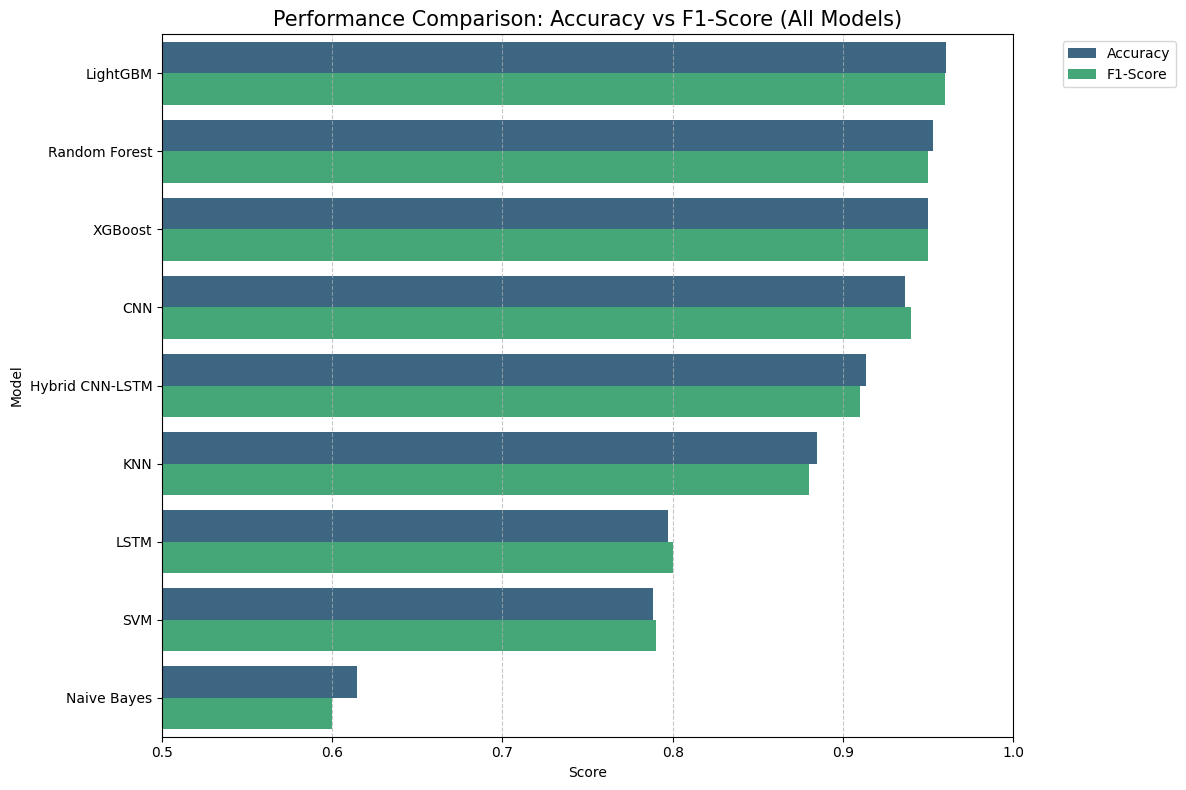

In [91]:
import pandas as pd
import seaborn as sns

# Data extracted from your notebook results
data = {
    'Model': ['LightGBM', 'Random Forest', 'XGBoost', 'CNN', 'Hybrid CNN-LSTM', 'KNN', 'LSTM', 'SVM', 'Naive Bayes'],
    'Accuracy': [0.9605, 0.9527, 0.9501, 0.9363, 0.9137, 0.8851, 0.7971, 0.7884, 0.6145],
    'F1-Score': [0.96, 0.95, 0.95, 0.94, 0.91, 0.88, 0.80, 0.79, 0.60]
}

df_results = pd.DataFrame(data).sort_values(by='Accuracy', ascending=False)
df_melted = df_results.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 8))
sns.barplot(data=df_melted, y='Model', x='Score', hue='Metric', palette='viridis')
plt.title('Performance Comparison: Accuracy vs F1-Score (All Models)', fontsize=15)
plt.xlim(0.5, 1.0) # Focus on the performance range
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
